In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RESULTS = ROOT / "results/station1"

# alle ViT-LoRA-Läufe, ohne die _history.json-Dateien
paths = [p for p in RESULTS.glob("vit_lora_r*.json") if not p.stem.endswith("_history")]
df = pd.DataFrame([json.loads(p.read_text()) for p in paths])

# Rang und Targets aus dem Namen, z. B. vit_lora_r8_qkv-proj -> 8, "qkv-proj"
parts = df["name"].str.extract(r"_r(\d+)_(.+)$")
df["rank"] = parts[0].astype(int)
df["targets"] = parts[1]
df = df.sort_values(["targets", "rank"])
df[["name", "targets", "rank", "test_acc", "trainable"]]

,name,rank,test_acc,trainable
2,vit_lora_r4_qkv-proj,4,0.710025,532621
0,vit_lora_r8_qkv-proj,8,0.714610,759949
1,vit_lora_r16_qkv-proj,16,0.703476,1214605
3,vit_lora_r32_qkv-proj,32,0.696322,2123917


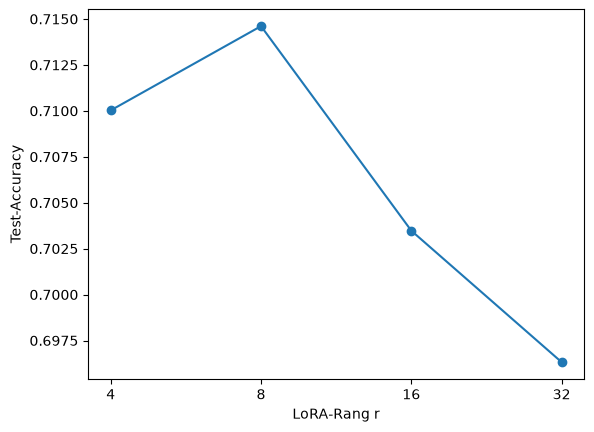

In [2]:
fig, ax = plt.subplots()

# eine Linie pro Target-Konfiguration, sortiert nach Anzahl trainierbarer Parameter
order = df.groupby("targets")["trainable"].min().sort_values().index
for targets in order:
    runs = df[df["targets"] == targets]
    ax.plot(runs["rank"], runs["test_acc"], marker="o", label=targets)

ranks = sorted(df["rank"].unique())
ax.set_xscale("log", base=2)  # Ränge verdoppeln sich (4, 8, 16, ...)
ax.set_xticks(ranks, labels=ranks)
ax.set_xlabel("LoRA-Rang r")
ax.set_ylabel("Test-Accuracy")
ax.legend(title="Targets")
fig.savefig(ROOT / "notebooks/results/station1/vit_lora_rank_vs_acc.png", dpi=150, bbox_inches="tight")